<a href="https://colab.research.google.com/github/cccano/sprint_8_proyecto_final/blob/main/S8_Student_Version_Project_NovaRetail.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto 7 - Explorando factores de comportamiento en NovaRetail+


NovaRetail+ es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios.

Para el cierre de 2024, el equipo de **Crecimiento y retención** tiene como objetivo responder:

**¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?**

> Este proyecto es un análisis **correlacional** (exploratorio).  
> **Correlación ≠ causalidad.**

## Sección 1 - Cargar y explorar el dataset

En esta sección validamos:
- que el dataset cargue correctamente
- tipos de datos
- valores faltantes / rangos generales

Antes de correlacionar, primero entendemos el “terreno”.

In [1]:
# Importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


### Cargar Dataset

In [12]:
# Cargar el dataset y explorar datos
df = pd.read_csv('/content/novaretail_comportamiento_clientes_2024.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


#### Descripción del conjunto de datos

El dataset contiene las siguientes columnas:

- `id_cliente` — Identificador único del cliente.
- `edad` — Edad del cliente.
- `nivel_ingreso` — Ingreso anual estimado del cliente.
- `visitas_mes` — Número de visitas a la aplicación o sitio web durante el mes.
- `compras_mes` — Número de compras realizadas en el mes.
- `gasto_publicidad_dirigida` — Gasto en anuncios asignado al usuario.
- `satisfaccion` — Calificación de satisfacción del cliente en una escala del 1 al 5.
- `miembro_premium` — Indica si el cliente tiene suscripción premium (1) o no (0).
- `abandono` — Indica si el cliente abandonó la plataforma (1) o no (0).
- `tipo_dispositivo` — Tipo de dispositivo utilizado por el cliente (móvil, escritorio o tablet).
- `region` — Región geográfica del cliente (norte, sur, oeste o este).
- `ingreso_anual` — Ingreso anual generado por el cliente para la empresa.

La métrica principal de análisis es `ingreso_anual`, utilizada para evaluar el impacto económico de los clientes.


In [13]:
# mostrar las primeras 5 filas
df.head(5)

,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


## Sección 2 - Preparar datos y documentar supuestos

### Exploración y Limpieza

#### Exploración inicial de los datos
El conjunto de datos contiene **15,000 registros** y **12 columnas**, sin valores nulos.

**Variables numéricas**  
Se identifican las siguientes columnas numéricas:
- `edad`
- 'nivel_ingreso'
- 'visitas_mes'
- 'compras_mes'
- 'gasto_publicidad_dirigida'
- 'satisfaccion'
- 'ingreso_anual'

La mayoría de estas variables presentan tipos de datos adecuados.  
Ninguna requiere algún cambio


**Variables binarias**  
Las siguientes columnas representan variables binarias:
- `miembro_premium`
- `abandono`

Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.

**Variables categóricas**  
Se identifican las siguientes columnas categóricas:
- `id_cliente`
- `tipo_dispositivo`
- `region`

Estas variables están correctamente definidas y no requieren transformación adicional.

In [14]:
#corregir variable de float a int

df['edad'] = df['edad'].astype('int64')

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  int64  
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(4), int64(5), object(3)
memory usage: 1.4+ MB


#### Explorar variables numéricas

In [ ]:
# Estadísticas descriptivas de variables numéricas
columnas_numericas = df.select_dtypes(include = ['int64','float64']).columns.tolist()
df[columnas_numericas].describe()


,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,ingreso_anual
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,38.262400,30019.704782,10.029000,1.206467,20.149301,3.603693,0.139267,0.150733,36.594180
std,11.492378,9833.166305,3.158189,1.105284,10.880724,0.685300,0.346236,0.357801,34.484888
min,18.000000,8000.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,30.000000,23127.097500,8.000000,0.000000,12.310000,3.100000,0.000000,0.000000,0.000000
50%,38.000000,30023.745000,10.000000,1.000000,19.730000,3.600000,0.000000,0.000000,30.705000
75%,46.000000,36768.440000,12.000000,2.000000,27.292500,4.100000,0.000000,0.000000,58.220000
max,75.000000,74790.840000,25.000000,8.000000,75.510000,5.000000,1.000000,1.000000,244.690000


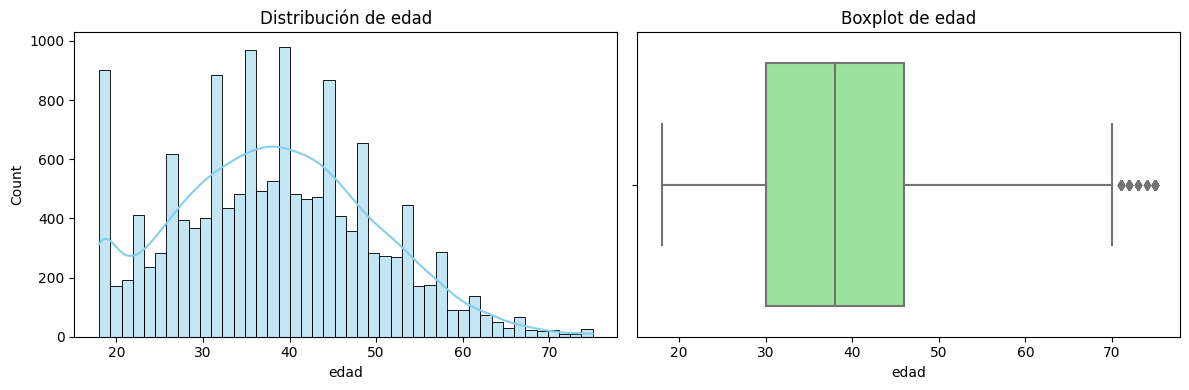

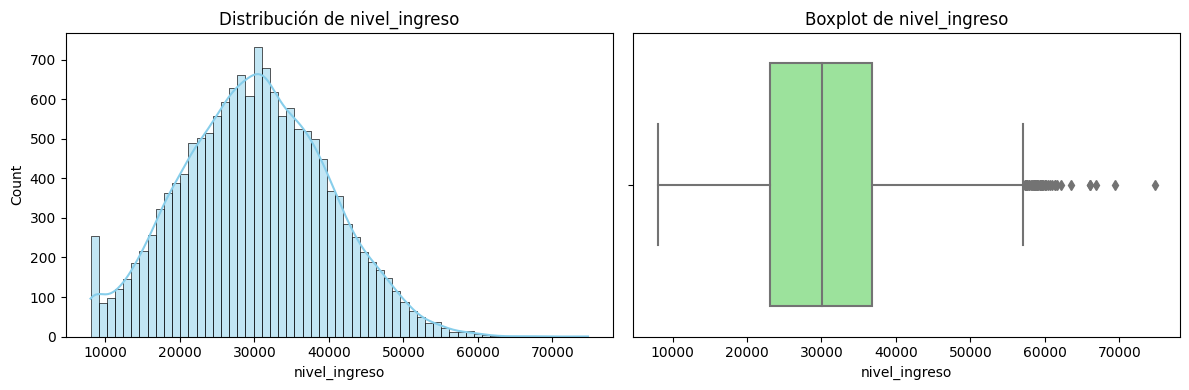

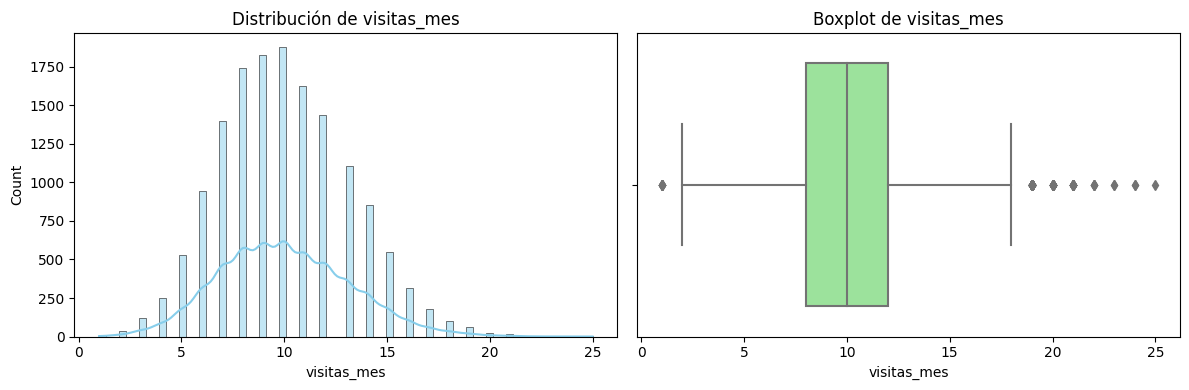

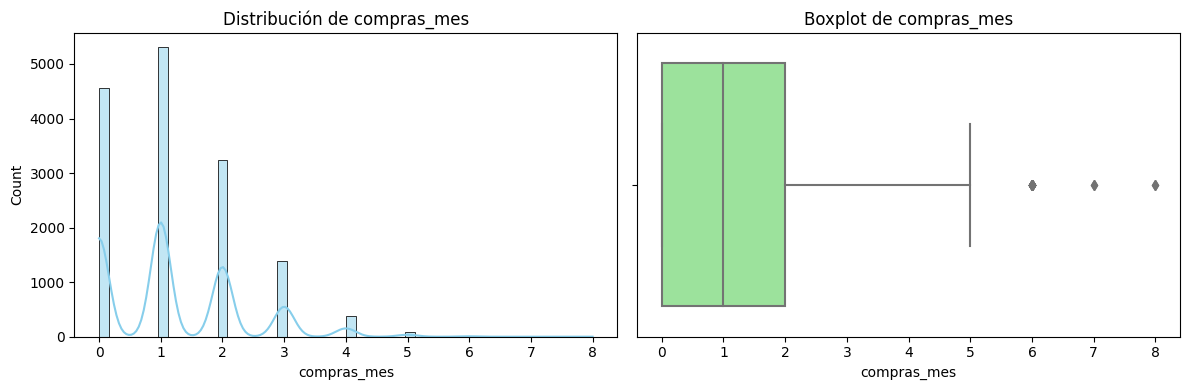

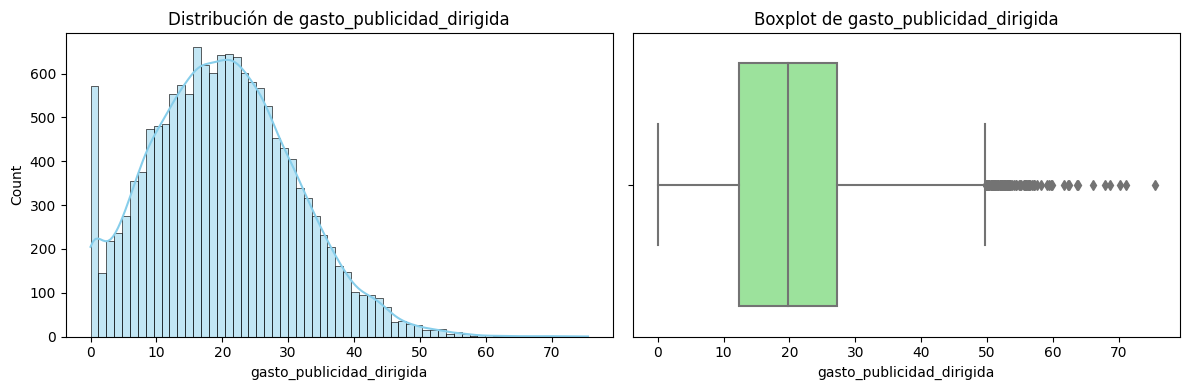

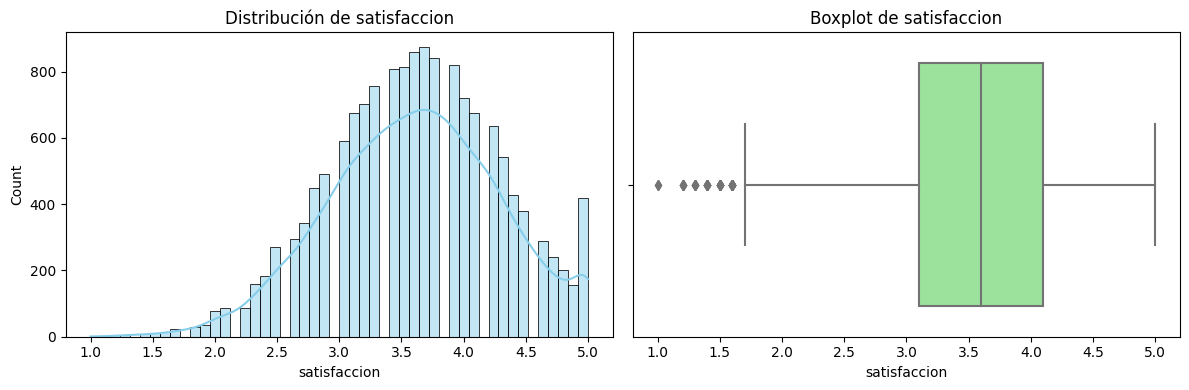

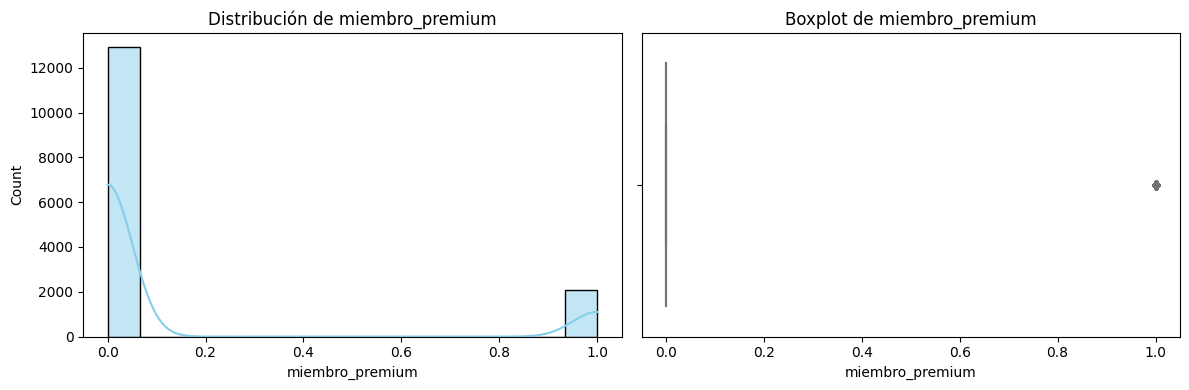

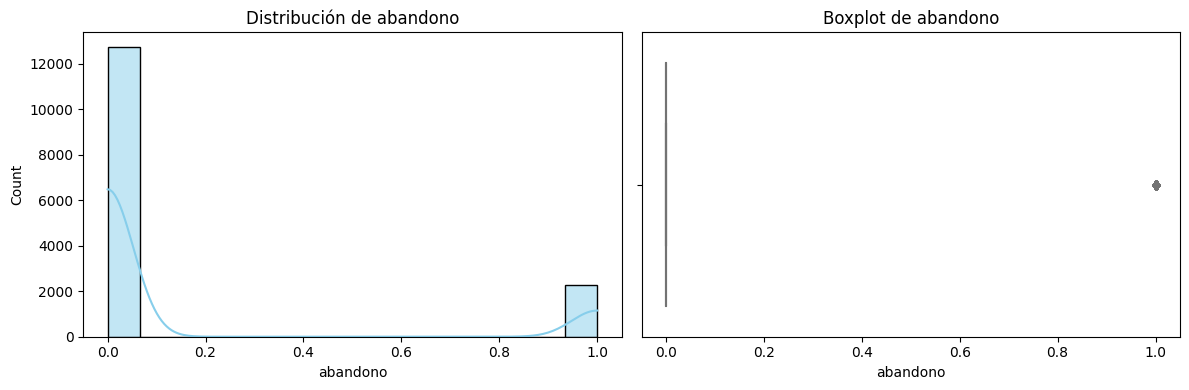

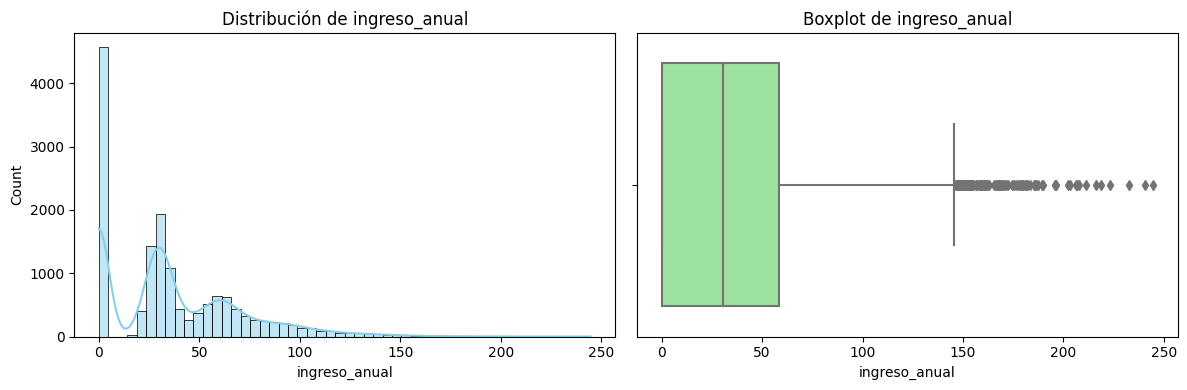

In [ ]:
for col in columnas_numericas:
    fig, axes = plt.subplots(1,2,figsize =  (12,4))
    sns.histplot(data = df, x = col, kde = True, ax = axes[0], color ='skyblue')
    axes[0].set_title(f'Distribución de {col}')

    sns.boxplot(data = df, x = col, ax = axes[1],  color = 'lightgreen')
    axes[1].set_title(f'Boxplot de {col}')

    plt.tight_layout()
    plt.show()

**Diagnóstico inicial de variables numéricas**

- `edad` — tiene un comportamiento plausible entre un valor minimo de 18 y maximo de 75. Pero presenta outliers superiores a 70.
- `nivel_ingreso`- Presenta un comportamiento razonable entre un valor minimo de 8000 y 74790. Pero presenta outliers superiores a 60000
- `visitias`- presentan un comportamiento casi simetrico a una distribución normal y destaca la presencia de outliers en ambos extremos.
- `compras_mes`- se observa que hay un alto número de usuarios que realizan entre 0 y 1 compra al mes y dando así a presentar outliers en el extremo superior.
- `gasto_publicidad_dirigida` - hay una tercera parte de los usuarios que no se les dirige gasto publicitario y presenta outliers con valores superiores a 50.
- `satisfaccion` - se presenta una distribución con una gran cantidad de usuarios con una calificación superior a 3, de tal manera que muestra oulierts en el extremo inferior.
- `ingreso_anual`- hay una tercera parte de los usuarios que no presentan un ingreso anual para la compañia y hay muy pocos usuarios que aportan ingresos superiores a 150 unidades monetarias anuales siendo estos outliers.

#### Explorar variables binarias

In [ ]:
# Verificar que cada columna tenga únicamente dos valores posibles
columnas_binarias = ['miembro_premium','abandono']

for col in columnas_binarias:
    print(col)
    print(df[col].value_counts())
    print('\n')

miembro_premium
0    12911
1     2089
Name: miembro_premium, dtype: int64


abandono
0    12739
1     2261
Name: abandono, dtype: int64




**Diagnóstico inicial de variables binarias**

- `miembro_premium` — la mayoria de los usuarios son de nivel premium siendo mas del 80 %.
- `abandono` — hay una cantidad importante de usuarios con abandono pero no representa ni la tercera parte del conjuto de datos.

#### Explorar variables categóricas

In [ ]:
# Verificar el número de valores únicos por variable categórica
lista_categorica = df.select_dtypes(include = ['category','object']).columns.tolist()

for col in lista_categorica:
    print(col)
    print(df[col].value_counts())
    print("\n")


id_cliente
CL-113278    1
CL-104298    1
CL-114882    1
CL-101572    1
CL-104365    1
            ..
CL-106645    1
CL-102847    1
CL-100309    1
CL-103555    1
CL-109170    1
Name: id_cliente, Length: 15000, dtype: int64


tipo_dispositivo
móvil         9818
escritorio    3720
tablet        1462
Name: tipo_dispositivo, dtype: int64


region
norte    4395
oeste    3810
sur      3726
este     3069
Name: region, dtype: int64




In [ ]:
# Explorar variables categóricas y cómo se distribuyen
for col in lista_categorica:
    print(col)
    print(df[col].describe())
    print("\n")

id_cliente
count         15000
unique        15000
top       CL-113278
freq              1
Name: id_cliente, dtype: object


tipo_dispositivo
count     15000
unique        3
top       móvil
freq       9818
Name: tipo_dispositivo, dtype: object


region
count     15000
unique        4
top       norte
freq       4395
Name: region, dtype: object




**Diagnóstico inicial de variables categóricas**

- `tipo_dispositivo` — el movil es tipo de dispositivo mas usado entre los usuarios, con mas de la mitad.
- `region` - las reiones son muy parejas en número de usuarios pero la región norte casi representa una tercera parte con 4395 usuarios.
-

### Supuestos

- El análisis se realiza utilizando **todo el conjunto de datos disponible**.
- Los datos no presentan errores y están correctamente tipificados.
- Se utilizan distintos coeficientes según el tipo de variable:
  - **Pearson** asume relaciones lineales entre variables numéricas.
  - **Spearman** evalúa relaciones monótonas y no requiere normalidad.
  - **Punto biserial** se usa para relaciones numérica–binaria.
  - **Cramér (V)** se usa para asociaciones entre variables categóricas.

**Supuesto central:**  
Este análisis identifica relaciones entre variables o segmentos, pero no prueba causalidad.

## Sección 3 - Visualización de relaciones

Observamos cómo se relacionan las variables numéricas.

### Heatmap

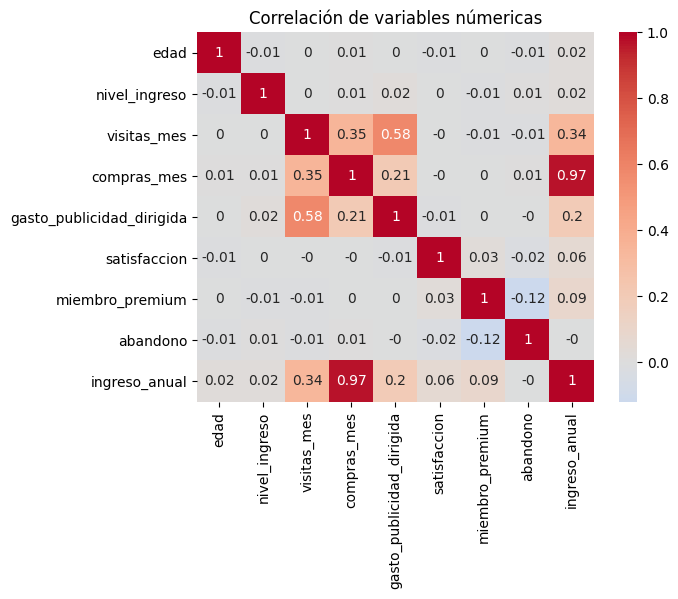

In [ ]:
# Visualizar la matriz de correlación para identificar relaciones
columnas_numericas = df.select_dtypes(include = ['int64','float64']).columns.tolist()
corr = df[columnas_numericas].corr().round(2)
sns.heatmap(corr, annot = True, cmap = 'coolwarm', center = 0)
plt.title('Correlación de variables númericas')
plt.show()


**Observaciones generales (Heatmap)**

- Se observa que el nivel de ingreso de los usuarios no tiene un relación líneal en la cantidad de compras al mes, sugiriendo así que los usuarios con ingresos altos no ncesariamente deberían ser los que mas compran.
- Las `visitas_mes` tiene una relación debil positiva con las `compras_mes`,`ingreso_anual` y una relación positiva moderada con `gasto_publicidad_dirigida`.
- El `gasto_publicidad_dirigida` tiene un relación debil positiva con `compras_mes`.
- La `satisfaccion` no tiene una relación observable con el número de compras del mes ni con la cantidad de visitas de los usuarios.

Observaciones respecto a `ingreso_anual`  
- Se presenta una colinealidad entre `compras_mes` e `ingreso_anual` lo cual se entiende debido a que las compras que se hagan en los meses afecta el resultado del ingreso anual generado de los usuarios a la compañia.
- El `ingreso_anual` presenta una realción moderada con `visitas_mes`, una relación positiva debil con `gasto_publicidad_dirigida`, y una relación muy insignificante repesto a la satisfacción del usuario.


### Scatterplot general

Con base en los resultados del análisis de correlación, evalúa si es necesario generar un *scatterplot* general.

- **Si decides incluirlo**:
  - Genera el gráfico.
  - Describe brevemente qué patrones o tendencias observas.

- **Si decides no incluirlo**:
  - Explica por qué.

### Scatterplot para pares clave

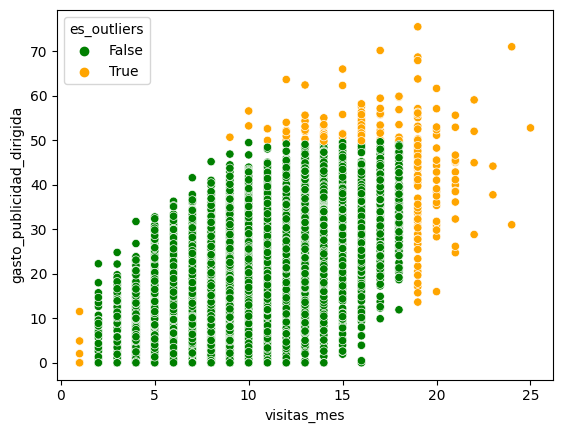

In [ ]:
# Visualizar pares de variables con relaciones moderadas o fuertes

def es_outliers(col):
    q1 = col.quantile(0.25)
    q3 = col.quantile(0.75)
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr
    return (col < limite_inferior) | (col > limite_superior)

df['es_outliers'] = es_outliers(df['visitas_mes']) | es_outliers(df['gasto_publicidad_dirigida'])

sns.scatterplot(data = df, x = 'visitas_mes', y = 'gasto_publicidad_dirigida',
                hue = 'es_outliers',palette = {False :'green',True :'orange'})

plt.show()



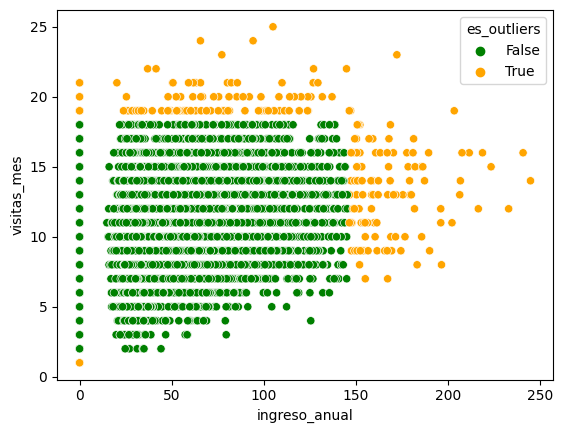

In [ ]:
def es_outliers(col):
    q1 = col.quantile(0.25)
    q3 = col.quantile(0.75)
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr
    return (col < limite_inferior) | (col > limite_superior)

df['es_outliers'] = es_outliers(df['ingreso_anual']) | es_outliers(df['visitas_mes'])

sns.scatterplot(data = df, x = 'ingreso_anual', y = 'visitas_mes',
                hue = 'es_outliers',palette = {False :'green',True :'orange'})

plt.show()

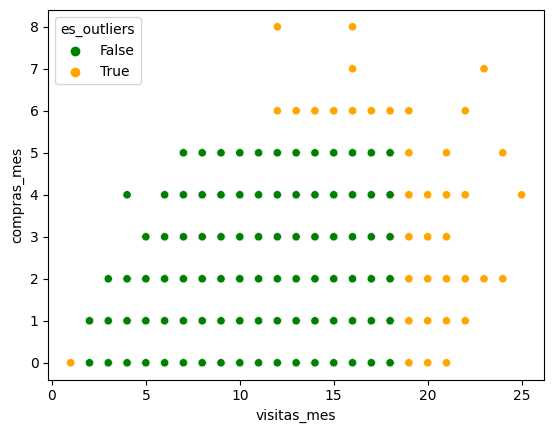

In [ ]:
def es_outliers(col):
    q1 = col.quantile(0.25)
    q3 = col.quantile(0.75)
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr
    return (col < limite_inferior) | (col > limite_superior)

df['es_outliers'] = es_outliers(df['visitas_mes']) | es_outliers(df['compras_mes'])

sns.scatterplot(data = df, x = 'visitas_mes', y = 'compras_mes',
                hue = 'es_outliers',palette = {False :'green',True :'orange'})

plt.show()

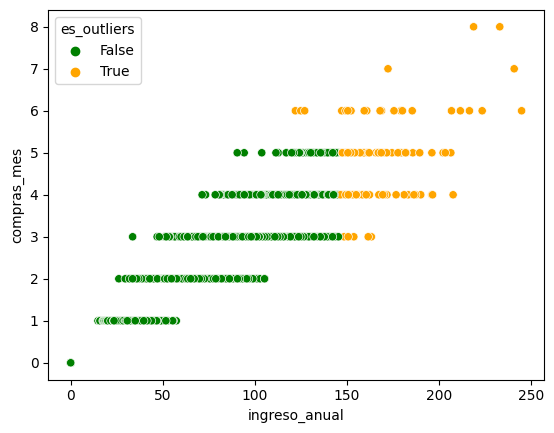

In [ ]:
def es_outliers(col):
    q1 = col.quantile(0.25)
    q3 = col.quantile(0.75)
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr
    return (col < limite_inferior) | (col > limite_superior)

df['es_outliers'] = es_outliers(df['ingreso_anual']) | es_outliers(df['compras_mes'])

sns.scatterplot(data = df, x = 'ingreso_anual', y = 'compras_mes',
                hue = 'es_outliers',palette = {False :'green',True :'orange'})

plt.show()

**Observaciones iniciales (Scatterplot)**

**visitas_mes vs gasto_publicidad_dirigida**
- Dirección positiva con dispersión media y presencia de outliers.
  
**visitas_mes vs ingreso_anual**
- Dirección positiva con una dispersión alta y presencia de outliers.

**visitas_mes vs compras_mes**
- Dirección positiva con una dispersión alta y presencia de outliers.
  
**ingreso_anual vs compras_mes**
- Dirección positiva con una dispersión baja, presencia de outliers y posible colinealidad.


## Sección 4 - Coeficientes de correlación y evidencia numérica

En esta sección, se reportan coeficientes que respaldan los patrones
observados visualmente, utilizando el método adecuado según el tipo
de variables.

### Pearson / Spearman

In [ ]:
# Calcular correlación entre variables relevantes
columnas_relevantes = ['visitas_mes','compras_mes',
                       'gasto_publicidad_dirigida','ingreso_anual']

def corr_numerica(df,columnas,metodo = 'pearson'):
    matriz = df[columnas].corr(method = metodo).round(2)
    return matriz.style.background_gradient(cmap = 'coolwarm')

corr_pearson = corr_numerica(df,columnas_relevantes)
corr_pearson


,visitas_mes,compras_mes,gasto_publicidad_dirigida,ingreso_anual
visitas_mes,1.000000,0.350000,0.580000,0.340000
compras_mes,0.350000,1.000000,0.210000,0.970000
gasto_publicidad_dirigida,0.580000,0.210000,1.000000,0.200000
ingreso_anual,0.340000,0.970000,0.200000,1.000000


In [ ]:
# Calcular correlación entre variables relevantes
def corr_numerica(df,columnas,metodo = 'spearman'):
    matriz = df[columnas].corr(method = metodo).round(2)
    return matriz.style.background_gradient(cmap = 'coolwarm')

corr_spearman = corr_numerica(df,columnas_relevantes)
corr_spearman

,visitas_mes,compras_mes,gasto_publicidad_dirigida,ingreso_anual
visitas_mes,1.000000,0.330000,0.560000,0.320000
compras_mes,0.330000,1.000000,0.190000,0.970000
gasto_publicidad_dirigida,0.560000,0.190000,1.000000,0.180000
ingreso_anual,0.320000,0.970000,0.180000,1.000000


**Observaciones de correlación**

**visitas_mes vs compras_mes**
- Correlación de pearson de 0.35 y de spearman de 0.33 con dirección positiva.

**visitas_mes vs gasto_publicidad_dirigida**
- Correlación de pearson de 0.58 y de spearman de 0.56 con dirección positiva.

**visitas_mes vs ingreso_anual**
- Correlación de pearson de 0.34 y de spearman de 0.32 con dirección positiva

**compras_mes vs gasto_publicidad_dirigida**
- Correlación de pearson de 0.21 y de spearman de 0.19 con dirección positiva

**ingreso_anual vs compras_mes**
- Correlación de pearson de 0.97 al igual que spearman con dirección positiva y posible colinealidad

**ingreso_anula vs gasto_publicidad_dirigida**
- Correlación de pearson de 0.20 y de spearman de 0.18 con dirección positiva

### Punto-biserial

In [ ]:
# Calcular correlación entre variables relevantes
from scipy.stats import pointbiserialr

for col in columnas_relevantes:
    print(f'miembro_premium vs {col}')
    print(pointbiserialr(df['miembro_premium'], df[col])[0])
    print('\n')

miembro_premium vs visitas_mes
-0.01265653458331907


miembro_premium vs compras_mes
0.003430536967706773


miembro_premium vs gasto_publicidad_dirigida
0.0027207774632817556


miembro_premium vs ingreso_anual
0.0930994396198015




In [ ]:
for col in columnas_relevantes:
    print(f'abandono vs {col}')
    print(pointbiserialr(df['abandono'], df[col])[0])
    print('\n')

abandono vs visitas_mes
-0.008942702975011398


abandono vs compras_mes
0.008290889319337781


abandono vs gasto_publicidad_dirigida
-0.004585823906401753


abandono vs ingreso_anual
-0.002823934021617148




**Observaciones Punto-biserial:**

Se realiza un calculo del punto biserial entre las variables binarias (miembro_premium y abandono) con respecto a las variables relevnates númericas. Se observa que con respecto a la variable `abandono` no hay una asociación singnificativa para con las variables númericas.

**miembro_premium vs visitas_mes**
- Relación muy debil y negativa, lo cual indica que no hay una diferencia entre un usuario premium y otro que no lo es respecto a visitar mas la página web.

**miembro_premium vs compras_mes**
- Relación positiva y muy debil indicando que los usuarios premium realizan la misma cantidad de compras que los usuarios no premium.

**miembro_premium vs gasto_publicidad_dirigida**
- Relación positiva y muy debil indicando que el gasto en plublicidad dirigido al usuario premium no tiene una diferencia relevante respecto al usuario no premium.

**miembro_premium vs ingreso_anual**
- elación positiva y muy debil indicando que los usuarios premium no representan un punto relevante para el ingreso anual que genera cada usuario a la compañia.

### V de Cramér

In [16]:
# Función para calcular V de Cramér
from scipy.stats import chi2_contingency

tabla = pd.crosstab(df['region'],df['tipo_dispositivo'])
tabla


tipo_dispositivo,escritorio,móvil,tablet
region,,,
este,766,2003,300
norte,1125,2843,427
oeste,935,2489,386
sur,894,2483,349


In [ ]:
# Aplicar V de Cramér en variables relevantes
chi2, p, dof, expected = chi2_contingency(tabla)
n = tabla.sum().sum()
cramer_v = np.sqrt(chi2/(n*(min(tabla.shape)-1)))
cramer_v

0.012378338407739397

In [17]:
tabla = pd.crosstab(df['abandono'],df['tipo_dispositivo'])
tabla

tipo_dispositivo,escritorio,móvil,tablet
abandono,,,
0,3149,8356,1234
1,571,1462,228


In [18]:
chi2, p, dof, expected = chi2_contingency(tabla)
n = tabla.sum().sum()
cramer_v = np.sqrt(chi2/(n*(min(tabla.shape)-1)))
cramer_v

np.float64(0.007245190431994803)

In [19]:
tabla = pd.crosstab(df['region'],df['abandono'])
tabla

abandono,0,1
region,,
este,2618,451
norte,3761,634
oeste,3210,600
sur,3150,576


In [20]:
chi2, p, dof, expected = chi2_contingency(tabla)
n = tabla.sum().sum()
cramer_v = np.sqrt(chi2/(n*(min(tabla.shape)-1)))
cramer_v

np.float64(0.015429712175030079)

In [21]:
tabla = pd.crosstab(df['miembro_premium'],df['abandono'])
tabla

abandono,0,1
miembro_premium,,
0,10741,2170
1,1998,91


In [22]:
chi2, p, dof, expected = chi2_contingency(tabla)
n = tabla.sum().sum()
cramer_v = np.sqrt(chi2/(n*(min(tabla.shape)-1)))
cramer_v

np.float64(0.12021874609740511)

**Observaciones V de Cramér**

Se observa una asociación muy debil positiva entre el tipo de dispositvo y la región, lo cual se da debido que los tipos de dispositivos se distribuyen en cada región de forma similar como se observa en la tabla de contingencia.

Tambien se observa una asociación muy debil possitava de la variabe `abandono` respecto a las variables categoricas.


## Sección 5 - Interpretación de resultados para el negocio

Cada hallazgo  debe incluir:
1) Evidencia visual (si aplica)
2) Evidencia numérica  
3) Interpretación (no causal)  
4) No podemos afirmar
5) Implicación de negocio

---

### Hallazgo 1 — Relación compras_mes vs ingreso_anual

**Evidencia visual**

![Imagen de captura de pantalla](/content/Captura de pantalla 2026-08-31 202712.png)


**Evidencia numérica:**

- coeficiente de correlación person de 0.97 y de sperman de 0.97
  
**Interpretación**
   
- presentan una asociación lineal muy fuerte, lo cual puede ser colinealidad.

**No podemos afirmar**  

- No podemos afirmar una causalidad de compras_mes respecto al ingreso_anual
  
**Implicación de negocio**  

- Activar estrategias de retención y analizar el comportamiento mensual del cliente.

### Hallazgo 2 — visitas_mes vs ingreso_anual

**Evidencia visual:**

![Imagen de captura de pantalla](/content/Captura de pantalla 2026-08-31 204037.png)

**Evidencia numérica:**

- Correlación de pearson de 0.34 y de spearman de 0.32 con dirección positiva
  
**Interpretación**

- Es una relación líneal positiva moderada.

**No podemos afirmar**  

- No se puede afirmar que el número de visitas sea causal del ingreso anual generado por usuario.
  
**Implicación de negocio**

- Entender que es lo que dispara el número de visitas por usuario y como esto se puedo traducir en consumo del mismo.

## Sección 6 - Limitaciones y próximos pasos

### **Limitaciones**
- Correlación ≠ causalidad
- Colinealidad entre compras_mes e ingreso_anual

### **Próximos pasos**

Probar segmentación adicional
- [opcion 1] segmentar el ingreso anual por región para observar una región destacable.
- [opcion 2] segmentar el ingreso anual por dispositivo para detectar en dispostivos se genera mas ingresos o compras.

[Paso 2]
- [opcion 1] segmentar el gasto en publicidad por dispositivo para verificar si la publicidad esta siendo dirigida mas a un tipo de dispositivo.
- [opcion 2] segmentar el gasto en publicidad por región para averiguar si hay una región que atrae mas gasto en publicidad.

[Paso 3]
- [opcion 1] Segmentar las visitas por dispositivo ya que puede haber un patrón destacable del usuario en esta observación.